# Práctica 1 NLP

## Configuración del entorno

In [ ]:
import pandas as pd
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import RandomOverSampler


nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


True

In [ ]:
#lectura de datos
df = pd.read_csv("amazon_reviews.csv")
df.head()

,Unnamed: 0,reviewerName,overall,reviewText,reviewTime,day_diff,helpful_yes,helpful_no,total_vote,score_pos_neg_diff,score_average_rating,wilson_lower_bound
0,0,NaN,4.0,No issues.,2014-07-23,138,0,0,0,0,0.0,0.0
1,1,0mie,5.0,"Purchased this for my device, it worked as adv...",2013-10-25,409,0,0,0,0,0.0,0.0
2,2,1K3,4.0,it works as expected. I should have sprung for...,2012-12-23,715,0,0,0,0,0.0,0.0
3,3,1m2,5.0,This think has worked out great.Had a diff. br...,2013-11-21,382,0,0,0,0,0.0,0.0
4,4,2&amp;1/2Men,5.0,"Bought it with Retail Packaging, arrived legit...",2013-07-13,513,0,0,0,0,0.0,0.0


## Exploración de datos

In [ ]:
# Aseguramos que el texto sea string y quitamos nulos
df['reviewText'] = df['reviewText'].fillna('').astype(str)

print("Información general del dataframe:")
print(df.info())

print("\nNúmero de valores nulos por columna:")
print(df.isnull().sum())

print("\nResumen estadístico:")
display(df.describe())

# Creamos una variable de sentimiento a partir de la puntuación overall
def convertir_sentimiento(rating):
    if rating >= 4:
        return 'positive'
    elif rating == 3:
        return 'neutral'
    else:
        return 'negative'

df['sentiment'] = df['overall'].apply(convertir_sentimiento)

print("\nDistribución del sentimiento:")
print(df['sentiment'].value_counts())

# Comprobamos la longitud de cada reseña
df['review_length'] = df['reviewText'].str.len()

df.groupby('sentiment')['review_length'].mean()

Información general del dataframe:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4915 entries, 0 to 4914
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Unnamed: 0            4915 non-null   int64  
 1   reviewerName          4914 non-null   object 
 2   overall               4915 non-null   float64
 3   reviewText            4915 non-null   object 
 4   reviewTime            4915 non-null   object 
 5   day_diff              4915 non-null   int64  
 6   helpful_yes           4915 non-null   int64  
 7   helpful_no            4915 non-null   int64  
 8   total_vote            4915 non-null   int64  
 9   score_pos_neg_diff    4915 non-null   int64  
 10  score_average_rating  4915 non-null   float64
 11  wilson_lower_bound    4915 non-null   float64
dtypes: float64(3), int64(6), object(3)
memory usage: 460.9+ KB
None

Número de valores nulos por columna:
Unnamed: 0              0
reviewerNam

,Unnamed: 0,overall,day_diff,helpful_yes,helpful_no,total_vote,score_pos_neg_diff,score_average_rating,wilson_lower_bound
count,4915.000000,4915.000000,4915.000000,4915.000000,4915.000000,4915.000000,4915.000000,4915.000000,4915.000000
mean,2457.000000,4.587589,437.367040,1.311089,0.210376,1.521465,1.100712,0.075468,0.020053
std,1418.982617,0.996845,209.439871,41.619161,4.023296,44.123095,39.367949,0.256062,0.077187
min,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,-130.000000,0.000000,0.000000
25%,1228.500000,5.000000,281.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,2457.000000,5.000000,431.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,3685.500000,5.000000,601.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,4914.000000,5.000000,1064.000000,1952.000000,183.000000,2020.000000,1884.000000,1.000000,0.957544



Distribución del sentimiento:
sentiment
positive    4449
negative     324
neutral      142
Name: count, dtype: int64


,review_length
sentiment,
negative,574.731481
neutral,390.098592
positive,241.425938


In [ ]:
#rellenamos el unico valor nulo que hay
df['reviewerName'] = df['reviewerName'].fillna('Unknown')

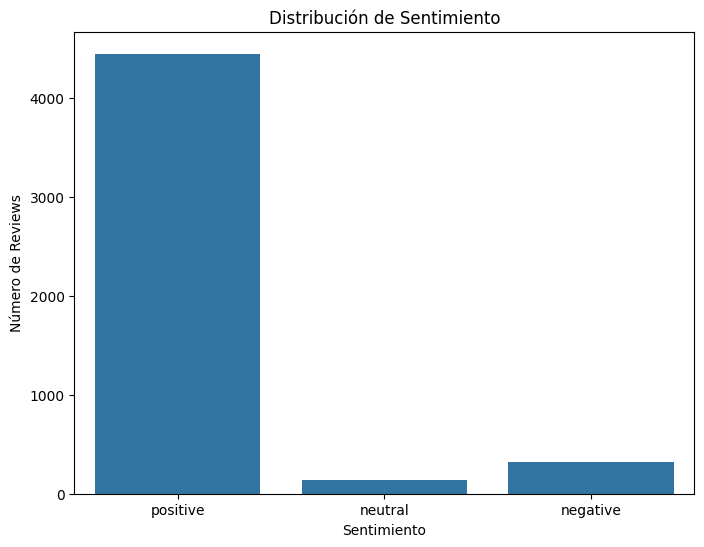

In [ ]:
#distribucion de sentimiento
plt.figure(figsize=(8, 6))
sns.countplot(x='sentiment', data=df, order=['positive', 'neutral', 'negative'])
plt.title('Distribución de Sentimiento')
plt.xlabel('Sentimiento')
plt.ylabel('Número de Reviews')
plt.show()

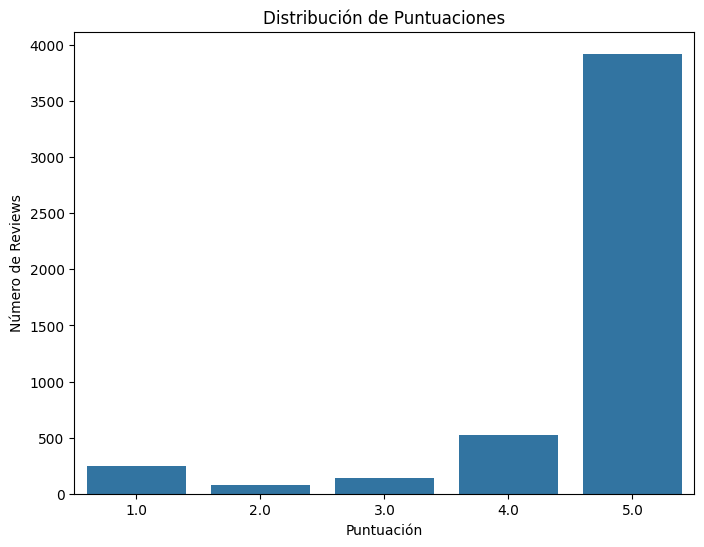

In [ ]:
# Distribución de puntuaciones
plt.figure(figsize=(8, 6))
sns.countplot(x='overall', data=df)
plt.title('Distribución de Puntuaciones')
plt.xlabel('Puntuación')
plt.ylabel('Número de Reviews')
plt.show()

In [ ]:
df.drop('Unnamed: 0', axis=1, inplace=True)

Eliminamos la variable Unnamed: 0 porque corresponde a un índice generado automáticamente durante la exportación

La variable de sentimiento se generó a partir de la valoración numérica (overall). Las puntuaciones de 4 y 5 se clasificaron como positivas, la puntuación 3 como neutral y las puntuaciones 1 y 2 como negativas. El análisis de la distribución de clases muestra un claro predominio de las opiniones positivas, lo que indica un desequilibrio entre categorías que puede influir en el rendimiento de los modelos de clasificación. También se aprecia que los usuarios insatisfechos tienden a proporcionar explicaciones más detalladas de sus experiencias, mientras que las opiniones positivas suelen ser más breves y directas.

## Preprocesamiento

In [ ]:
# Stopwords en inglés
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    # Tokenización
    if not isinstance(text, float):
        tokens = word_tokenize(text.lower())

        # Eliminación de stopwords y lematización
        tokens = [
            lemmatizer.lemmatize(word)
            for word in tokens
            if word not in stop_words and word.isalnum()
        ]

        return ' '.join(tokens)
    else:
        return ''

# Aplicar preprocesamiento a las reviews
df['clean_review'] = df['reviewText'].apply(preprocess_text)

# Mostrar ejemplos
for idx, text in enumerate(df['clean_review']):
    if idx >= 7:
        break
    print(text)

issue
purchased device worked advertised never much phone memory since download lot stuff brainer
work expected sprung higher capacity think made bit cheesier earlier version paint look clean
think worked diff bran 64gb card went south 3 one held pretty well since s3 note3 update month zero issue since transferred s3 note3 note2 card reliable solid cheer
bought retail packaging arrived legit orange envelope english version asian like picture show arrived quickly bought 32 16 retail packaging htc one sv lg optimus card working order probably best price get nice sd card
mini storage anything else supposed purchased add additional storage microsoft surface pro tablet come 64 128 gb supposed sandisk long standing reputation speaks
phone never skip beat file transfer speedy corruption issue memory fade issue would expect sandisk brand great card entrust precious file slightly cheaper piece crap lose everything forgive spending extra couple buck trusted product go good qa


## Modelado

In [ ]:
# Separar variables predictoras y variable objetivo
X = df['clean_review']
y = df['sentiment']

# Balancear el conjunto de datos con sobremuestreo
oversampler = RandomOverSampler(random_state=42)

X_balanced, y_balanced = oversampler.fit_resample(
    X.values.reshape(-1, 1),
    y
)

# Separar entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X_balanced.flatten(),
    y_balanced,
    test_size=0.2,
    random_state=42
)

# Vectorización TF-IDF
vectorizer = TfidfVectorizer()

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

# Modelo de Regresión Logística
model = LogisticRegression(
    multi_class='ovr',
    class_weight='balanced',
    max_iter=1000
)

model.fit(X_train_tfidf, y_train)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


LogisticRegression(class_weight='balanced', max_iter=1000, multi_class='ovr')

En esta fase se separan las variables del modelo. La variable independiente corresponde a las reseñas preprocesadas almacenadas en clean_review, mientras que la variable objetivo es sentiment. Debido al desequilibrio observado entre las clases, se aplica sobremuestreo aleatorio mediante RandomOverSampler, generando nuevas muestras de las clases minoritarias. Posteriormente, los datos se dividen en entrenamiento y prueba. Finalmente, se aplica TF-IDF para transformar los textos en vectores numéricos y se entrena un modelo de regresión logística para clasificar las reseñas según su polaridad.

## Evaluación

Reporte de Clasificación:
              precision    recall  f1-score   support

    negative       0.97      0.99      0.98       908
     neutral       0.96      1.00      0.98       857
    positive       0.99      0.93      0.96       905

    accuracy                           0.97      2670
   macro avg       0.98      0.98      0.97      2670
weighted avg       0.98      0.97      0.97      2670



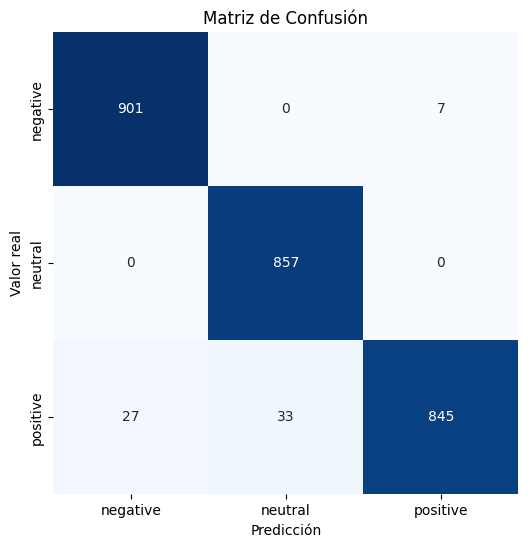

In [ ]:
# Evaluación del modelo
y_pred = model.predict(X_test_tfidf)

# Reporte de clasificación
print("Reporte de Clasificación:")
print(classification_report(y_test, y_pred))

# Matriz de confusión
conf_matrix = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 6))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=False,
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel('Predicción')
plt.ylabel('Valor real')
plt.title('Matriz de Confusión')
plt.show()

El modelo de regresión logística entrenado sobre representaciones TF-IDF obtuvo un rendimiento muy elevado. La precisión global alcanzó un valor del 97%, lo que indica una elevada capacidad para identificar correctamente la polaridad de las reseñas.

El análisis por clases muestra resultados equilibrados. La categoría negativa obtuvo una precisión del 97%, un recall del 99% y un F1-score del 98%. La categoría neutral alcanzó un recall del 100%, indicando que todas las reseñas neutrales fueron correctamente identificadas. Por su parte, la categoría positiva presentó una precisión del 99% y un F1-score del 96%.

La matriz de confusión confirma estos resultados, mostrando un número muy reducido de errores de clasificación. La mayoría de las observaciones se concentran en la diagonal principal, correspondiente a las predicciones correctas. Los errores se producen principalmente cuando algunas reseñas positivas son clasificadas como negativas o neutrales.
